# Chapter 12 - Mixture Models

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#12.2.1-Simulation-of-Two-Type-Mixture" data-toc-modified-id="12.2.1-Simulation-of-Two-Type-Mixture-1">12.2.1 Simulation of Two-Type Mixture</a></span></li><li><span><a href="#12.2.2-Knowing-the-Component-Distributions" data-toc-modified-id="12.2.2-Knowing-the-Component-Distributions-2">12.2.2 Knowing the Component Distributions</a></span></li><li><span><a href="#12.2.3-Observing-Multiple-Signals" data-toc-modified-id="12.2.3-Observing-Multiple-Signals-3">12.2.3 Observing Multiple Signals</a></span></li><li><span><a href="#12.3.2-Simulation-of-Two-Signal-Data" data-toc-modified-id="12.3.2-Simulation-of-Two-Signal-Data-4">12.3.2 Simulation of Two Signal Data</a></span></li><li><span><a href="#12.3.6-Mixture-Model-Estimator-in-Python" data-toc-modified-id="12.3.6-Mixture-Model-Estimator-in-Python-5">12.3.6 Mixture Model Estimator in Python</a></span></li><li><span><a href="#12.4.2-Twin-Reports-Data" data-toc-modified-id="12.4.2-Twin-Reports-Data-6">12.4.2 Twin Reports Data</a></span></li><li><span><a href="#12.4.3-Mixture-Model-Approach-to-Measurement-Error" data-toc-modified-id="12.4.3-Mixture-Model-Approach-to-Measurement-Error-7">12.4.3 Mixture Model Approach to Measurement Error</a></span></li><li><span><a href="#12.4.4-Estimating-Returns-to-Schooling-from-Twins" data-toc-modified-id="12.4.4-Estimating-Returns-to-Schooling-from-Twins-8">12.4.4 Estimating Returns to Schooling from Twins</a></span></li><li><span><a href="#12.5.1-Restaurant-Employment" data-toc-modified-id="12.5.1-Restaurant-Employment-9">12.5.1 Restaurant Employment</a></span></li><li><span><a href="#12.5.2-Mixture-Model-Estimation-of-Restaurant-Type" data-toc-modified-id="12.5.2-Mixture-Model-Estimation-of-Restaurant-Type-10">12.5.2 Mixture Model Estimation of Restaurant Type</a></span></li><li><span><a href="#12.5.3-Heterogeneous-Minimum-Wage-Effect" data-toc-modified-id="12.5.3-Heterogeneous-Minimum-Wage-Effect-11">12.5.3 Heterogeneous Minimum Wage Effect</a></span></li></ul></div>

## 12.2.1 Simulation of Two-Type Mixture

In [1]:
# as in the previous chapters, we use numpy
import numpy as np

In [2]:
# remove Python warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

N = 10000
mu = np.array([0, 10, -1, 3])
# diagonal matrix with different variances.
Sig = np.diag([2, 1, 3, 1])

# four columns drawn from normal distributions
# rmvnorm of the R package mvtnorm is np.random.multivariate_normal in numpy
x = np.random.multivariate_normal(mu, Sig, N)

# alpha is the probability of the first hidden type
alpha = 0.4
ranN = np.random.rand(N)

# the two observed outcomes come from the same hidden type
# first type: y1 is the 1st column of x and y2 is the 3rd column
# second type: y1 is the 2nd column of x and y2 is the 4th column
# python starts counting at 0, so the columns are 0, 1, 2 and 3
y1 = np.where(ranN < alpha, x[:, 0], x[:, 1])
y2 = np.where(ranN < alpha, x[:, 2], x[:, 3])

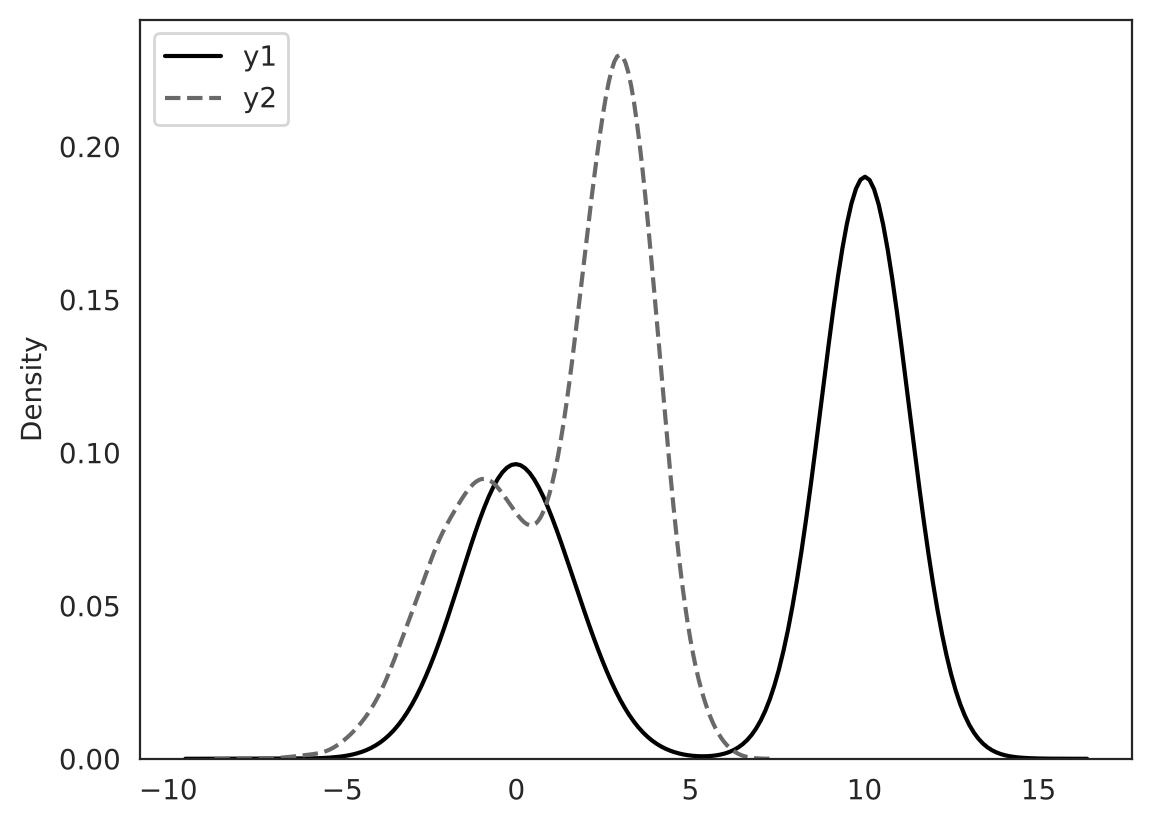

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# plotting with a R-looking plotting style
sns.set_style('white')

# density of the two mixture distributions
sns.kdeplot(y1, color='k', label='y1')
sns.kdeplot(y2, color='dimgray', linestyle='--', label='y2')
plt.ylabel('Density')
plt.legend(loc='upper left')
plt.show()

## 12.2.2 Knowing the Component Distributions

R has a `density()` function which returns the values of the density on a grid of 512 points. We write the same function by hand, with the bandwidth and the grid of R, to find the numbers of the book in section 12.5.

In [5]:
from scipy import stats

def density(x, from_x=None, to_x=None, n=512):
    """
    Kernel density with a normal kernel, as density() in R
    * x is the vector of observations
    * the density is computed at n points between from_x and to_x
      ("from" is a reserved word in Python, so we call it from_x)
    * returns the n points and the density at these n points
    """

    x = np.array(x, dtype=float)
    N_x = len(x)  # number of observations

    # bandwidth of the kernel, with the default rule of R (bw.nrd0)
    # R's sd divides by n-1 (ddof=1 in numpy)
    sd_x = np.std(x, ddof=1)
    iqr_x = np.quantile(x, 0.75) - np.quantile(x, 0.25)
    spread = min(sd_x, iqr_x/1.34)
    # with many equal values the spread can be 0
    # R then takes the standard deviation, then the first value of x, then 1
    if spread == 0:
        spread = sd_x
    if spread == 0:
        spread = abs(x[0])
    if spread == 0:
        spread = 1
    bw = 0.9*spread*N_x**(-0.2)

    # by default the points go 3 bandwidths further than the data
    if from_x is None:
        from_x = np.min(x) - 3*bw
    if to_x is None:
        to_x = np.max(x) + 3*bw

    # R does not put a kernel around each observation (too slow with many observations)
    # it first moves the observations to a grid of n points
    # the grid is 4 bandwidths wider than what we ask for, on each side
    lo = from_x - 4*bw
    up = to_x + 4*bw
    grid = np.linspace(lo, up, n)
    step = (up - lo)/(n - 1)

    # each observation is shared between the two points of the grid around it
    # the closest point gets the largest share
    weight = np.zeros(n)
    for x_i in x:
        pos = (x_i - lo)/step
        left = int(np.floor(pos))  # point of the grid on the left of x_i
        share = pos - left
        # an observation outside the grid is left out (there is none in this chapter)
        if left >= 0 and left < n - 1:
            weight[left] = weight[left] + (1 - share)/N_x
            weight[left + 1] = weight[left + 1] + share/N_x

    # distance between all the pairs of points of the grid (a matrix n x n)
    dist = grid.reshape(n, 1) - grid.reshape(1, n)
    # density at each point of the grid:
    # a normal kernel around every point of the grid, times the weight of this point
    dens = stats.norm.pdf(dist, scale=bw).dot(weight)

    # the n points we ask for, and the density at these points
    # (np.interp draws a straight line between two points of the grid)
    out_x = np.linspace(from_x, to_x, n)
    out_y = np.interp(out_x, grid, dens)

    return out_x, out_y

In [6]:
q_y2 = np.quantile(y2, 0.5)

# density of y2 on the grid
d_x, d_y = density(y2)

# in the book the element 315 of the grid is about the median
# our random numbers are not the same,
# so we look for the point of the grid which is the closest to the median
a1 = d_y[np.argmin((d_x - q_y2)**2)]

# density of the two known components at the median
# loc is the mean and scale is the standard deviation
b1 = stats.norm.pdf(q_y2, loc=3)
c1 = stats.norm.pdf(q_y2, loc=-1, scale=3**0.5)

# estimate of alpha (the true value is 0.4)
print((a1 - b1)/(c1 - b1))

0.39802737987577563


## 12.2.3 Observing Multiple Signals

In [7]:
min1 = min(np.min(y1), np.min(y2))
max1 = max(np.max(y1), np.max(y2))
K1 = 10
K2 = 7
eps = 1e-5
del1 = (max1 - min1)/K1
del2 = (max1 - min1)/K2

# conditional probability matrix
# np.full creates a matrix of NAs (np.nan in python)
prob_mat = np.full((K2+1, K1+1), np.nan)
# actual hidden type conditional probability matrix
prob_mat_x = np.full((K2+1, 3), np.nan)

low1 = min1 - eps
high1 = low1 + eps + del1
# python starts counting at 0: the row 0 and the column 0 have the middle
# of the cells, and the loops go from 1 to K1 and from 1 to K2 as in R
for k1 in range(1, K1+1):
    low2 = min1 - eps
    high2 = low2 + eps + del2
    prob_mat[0, k1] = (low1 + high1)/2
    y1_c = y1[(y2 > low1) & (y2 < high1)]  # conditioning
    for k2 in range(1, K2+1):
        prob_mat[k2, 0] = (low2 + high2)/2
        # probability conditional on 2nd signal
        # the mean of a True/False variable gives the probability
        # when no y2 is in the cell, the mean is nan (as in R)
        prob_mat[k2, k1] = np.mean((y1_c > low2) & (y1_c < high2))
        # probabilities conditional on actual hidden type.
        prob_mat_x[k2, 1] = np.mean((x[:, 0] > low2) & (x[:, 0] < high2))
        prob_mat_x[k2, 2] = np.mean((x[:, 1] > low2) & (x[:, 1] < high2))
        low2 = high2 - eps
        high2 = low2 + eps + del2
    low1 = high1 - eps
    high1 = low1 + eps + del1

prob_mat_x[:, 0] = prob_mat[:, 0]

In [8]:
import pandas as pd

# first row: middle of each cell of y2
# first column: middle of each cell of y1
pd.DataFrame(prob_mat).round(3)

,0,1,2,3,4,5,6,7,8,9,10
0,NaN,-6.476,-4.320,-2.164,-0.008,2.148,4.304,6.460,8.617,10.773,12.929
1,-6.014,0.000,0.000,0.002,0.000,0.000,0.000,0.000,NaN,NaN,NaN
2,-2.934,0.000,0.153,0.155,0.156,0.018,0.001,0.000,NaN,NaN,NaN
3,0.146,0.812,0.737,0.709,0.647,0.074,0.009,0.000,NaN,NaN,NaN
4,3.226,0.188,0.109,0.134,0.109,0.017,0.001,0.000,NaN,NaN,NaN
5,6.306,0.000,0.000,0.001,0.002,0.013,0.016,0.034,NaN,NaN,NaN
6,9.387,0.000,0.000,0.000,0.066,0.719,0.805,0.797,NaN,NaN,NaN
7,12.467,0.000,0.000,0.000,0.021,0.158,0.166,0.169,NaN,NaN,NaN


In [9]:
# first column: middle of each cell of y1
# second and third columns: probabilities for each hidden type
pd.DataFrame(prob_mat_x).round(3)

,0,1,2
0,NaN,NaN,NaN
1,-6.014,0.001,0.000
2,-2.934,0.157,0.000
3,0.146,0.722,0.000
4,3.226,0.120,0.000
5,6.306,0.000,0.016
6,9.387,0.000,0.808
7,12.467,0.000,0.176


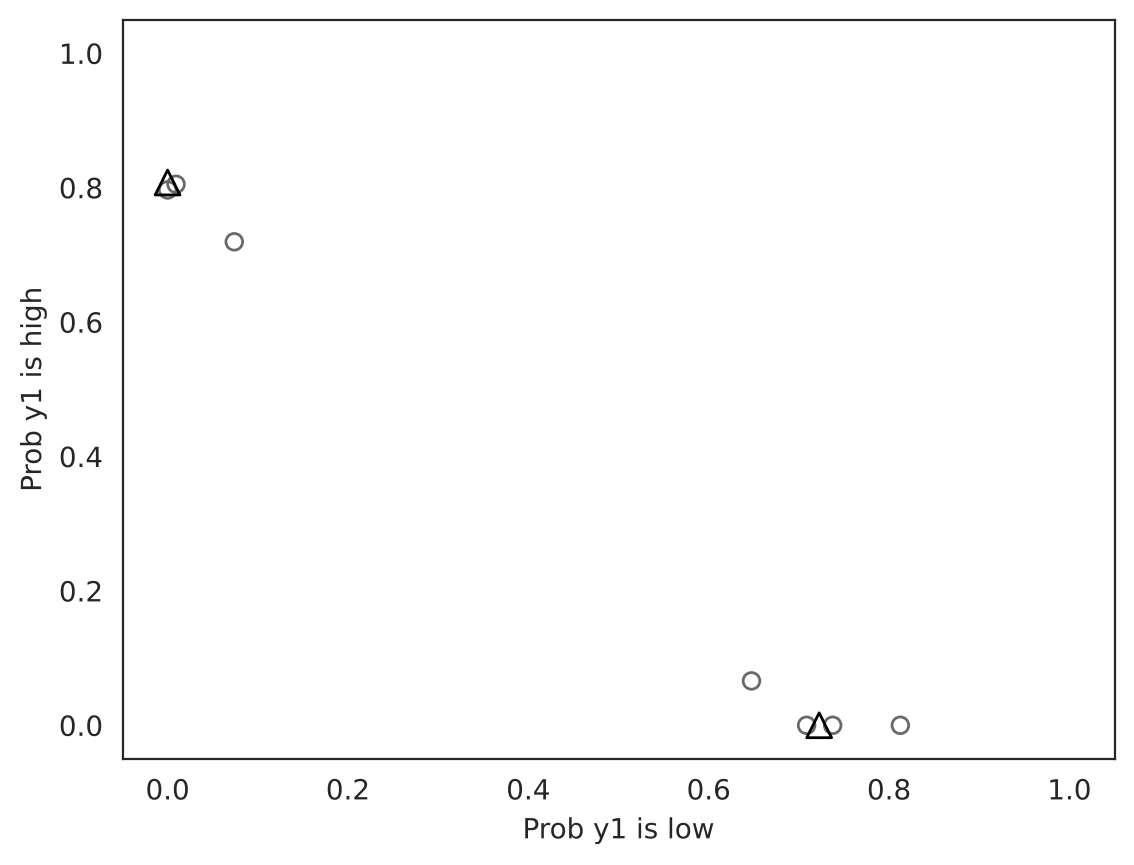

In [10]:
# we take one cell where y1 is low and one cell where y1 is high
# (rows 3 and 6 of prob_mat: y1 around 0.1 and y1 around 9.4)
row_low = 3
row_high = 6

# circles: probabilities of the two cells for each value of y2 (observed)
plt.scatter(prob_mat[row_low, 1:], prob_mat[row_high, 1:],
            facecolors='none', color='dimgray')

# triangles: probabilities of the two cells for each hidden type (not observed)
plt.scatter(prob_mat_x[row_low, 1:], prob_mat_x[row_high, 1:],
            marker='^', s=80, facecolors='none', color='k')

plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.xlabel('Prob y1 is low')
plt.ylabel('Prob y1 is high')
plt.show()

## 12.3.2 Simulation of Two Signal Data

The R code of the book compares `ranN` with the probabilities `p` and not with their running sum, so no observation gets the type 3 (the types are 1, 2 and 4, with probabilities 0.2, 0.3 and 0.5), and we keep it this way to stay close to the numbers of the book.

In [11]:
np.random.seed(123456789)

N = 10000
u = np.array([1, 2, 3, 4])
p = np.array([0.2, 0.5, .25, 0.05])
ranN = np.random.rand(N)

# hidden type of each observation
# np.where is the ifelse of R
theta = np.where(ranN < p[0], u[0],
                 np.where(ranN < p[1], u[1],
                          np.where(ranN < p[2], u[2], u[3])))

# two signals of the hidden type
e1 = np.random.normal(loc=0, scale=0.3, size=N)
e2 = np.random.normal(loc=0, scale=0.3, size=N)
x1 = 1 + .25*theta + e1
x2 = 0.5 + 0.1*theta + e2

In [12]:
pd.Series(x1).describe()

count    10000.000000
mean         1.705918
std          0.428617
min          0.232635
25%          1.390504
50%          1.724045
75%          2.022661
max          3.057132
dtype: float64

In [13]:
pd.Series(x2).describe()

count    10000.000000
mean         0.785714
std          0.324061
min         -0.810731
25%          0.558186
50%          0.787055
75%          1.010087
max          2.026701
dtype: float64

## 12.3.6 Mixture Model Estimator in Python

R's `kmeans()` uses the algorithm of Hartigan and Wong, which does not always stop at the same groups as `KMeans` of sklearn (Lloyd's algorithm). The mixture model depends on the groups it starts from, so we write a short version of the R algorithm by hand.

In [14]:
def kmeans(X, centers):
    """
    Groups the observations around the centers (short version of kmeans() in R)
    * X is a matrix with one row per observation
    * centers is a matrix with one row per group (the starting points)
    * returns the group of each observation: 0, 1, 2, ...
    """

    X = np.array(X, dtype=float)
    centers = np.array(centers, dtype=float)
    N = X.shape[0]  # number of observations
    K = centers.shape[0]  # number of groups

    # at the start each observation goes to the closest center
    t1 = np.zeros(N, dtype=int)
    for i in range(0, N):
        t1[i] = np.argmin(np.sum((centers - X[i, :])**2, axis=1))

    # number of observations and mean of each group
    n_k = np.zeros(K)
    for k in range(0, K):
        n_k[k] = np.sum(t1 == k)
        centers[k, :] = np.mean(X[t1 == k, :], axis=0)

    # we take the observations one by one
    # an observation changes group when this lowers the sum of squares
    # we stop when no observation moves anymore
    moved = True
    while moved:
        moved = False
        for i in range(0, N):
            k1 = t1[i]  # current group
            if n_k[k1] > 1:
                # squared distance to the mean of each group
                d = np.sum((centers - X[i, :])**2, axis=1)
                # fall in the sum of squares if the observation leaves its group
                cost_leave = d[k1]*n_k[k1]/(n_k[k1] - 1)
                # rise in the sum of squares if it joins another group
                cost_join = d*n_k/(n_k + 1)
                cost_join[k1] = np.inf
                k2 = np.argmin(cost_join)  # best other group
                if cost_join[k2] < cost_leave:
                    # the observation moves from k1 to k2
                    # we update the means and the sizes of the two groups
                    centers[k1, :] = (centers[k1, :]*n_k[k1] - X[i, :])/(n_k[k1] - 1)
                    centers[k2, :] = (centers[k2, :]*n_k[k2] + X[i, :])/(n_k[k2] + 1)
                    n_k[k1] = n_k[k1] - 1
                    n_k[k2] = n_k[k2] + 1
                    t1[i] = k2
                    moved = True

    return t1

In [15]:
def mixmod_fun(X, centers=2, tol=1e-9, maxiter=500, verb=False):
    """
    Mixture model estimator
    * X is a matrix with one row per observation and one column per signal
    * centers is a matrix with one row per hidden type (starting points
      of kmeans), or the number of hidden types
    * returns the prior g, the posterior gamma and the type t of each observation
    * python starts counting at 0, so the types are 0, 1, 2, ...
    """

    X = np.array(X, dtype=float)
    N = X.shape[0]  # number of observations
    J = X.shape[1]  # number of signals

    # the function accepts either a matrix or just the number
    # of hidden types.
    if np.ndim(centers) == 0:
        K = centers
        # as R's kmeans, we start from K rows of X taken at random
        centers = X[np.random.choice(N, K, replace=False), :]
    else:
        centers = np.array(centers, dtype=float)
        K = centers.shape[0]

    # find the initial set of types using kmeans().
    t1 = kmeans(X, centers)
    # T1 has one column per type: 1 if the observation is of this type
    T1 = np.zeros((N, K))
    for k in range(0, K):
        T1[:, k] = np.where(t1 == k, 1, 0)

    # determine the initial prior estimate
    # (mean of each column, colMeans in R)
    g1 = np.mean(T1, axis=0)

    # the likelihood functions are computed on a grid of 512 points
    # from min(X) to max(X). The grid does not change in the loop,
    # so we look once for the point of the grid closest to each observation
    grid = np.linspace(np.min(X), np.max(X), 512)
    index = np.zeros((N, J), dtype=int)
    for row in range(0, N):
        for j in range(0, J):
            index[row, j] = np.argmin((grid - X[row, j])**2)

    # loop to calculate the prior and posterior
    diff = np.sum(np.abs(1 - g1))
    i = 0
    while diff > tol and i < maxiter:

        # calculate the posterior
        # we start with a matrix with N rows, each row is the prior
        gamma = np.tile(g1, (N, 1))

        # calculate the likelihood functions
        for k in range(0, K):
            for j in range(0, J):
                # density of signal j for the observations of type k
                h1_x, h1_y = density(X[t1 == k, j],
                                     from_x=np.min(X), to_x=np.max(X))
                h1_y = h1_y/np.sum(h1_y)
                # likelihood of each observation: the density at the
                # closest point of the grid
                gamma[:, k] = gamma[:, k]*h1_y[index[:, j]]
        # each row is divided by its sum (rowSums in R)
        gamma = gamma/np.sum(gamma, axis=1).reshape(N, 1)

        # update the categorization of types
        # the type with the highest posterior (max.col in R)
        t1 = np.argmax(gamma, axis=1)

        # update the prior estimate
        g2 = np.mean(gamma, axis=0)

        # check for convergence
        diff = np.sum(np.abs(g1 - g2))
        g1 = g2
        i = i + 1
        if verb:
            print(diff)
            print(i)

    # R returns a list, we return a dictionary
    return {'g': g2, 'gamma': gamma, 't': t1}

In [16]:
# np.c_ puts the two vectors in the columns of a matrix (cbind in R)
centers = np.c_[1 + 0.25*u, 0.5 + 0.1*u]
# columns are number of signals (2 in this case)
# rows are number of types (4 in this case.)
a = mixmod_fun(X=np.c_[x1, x2], centers=centers)

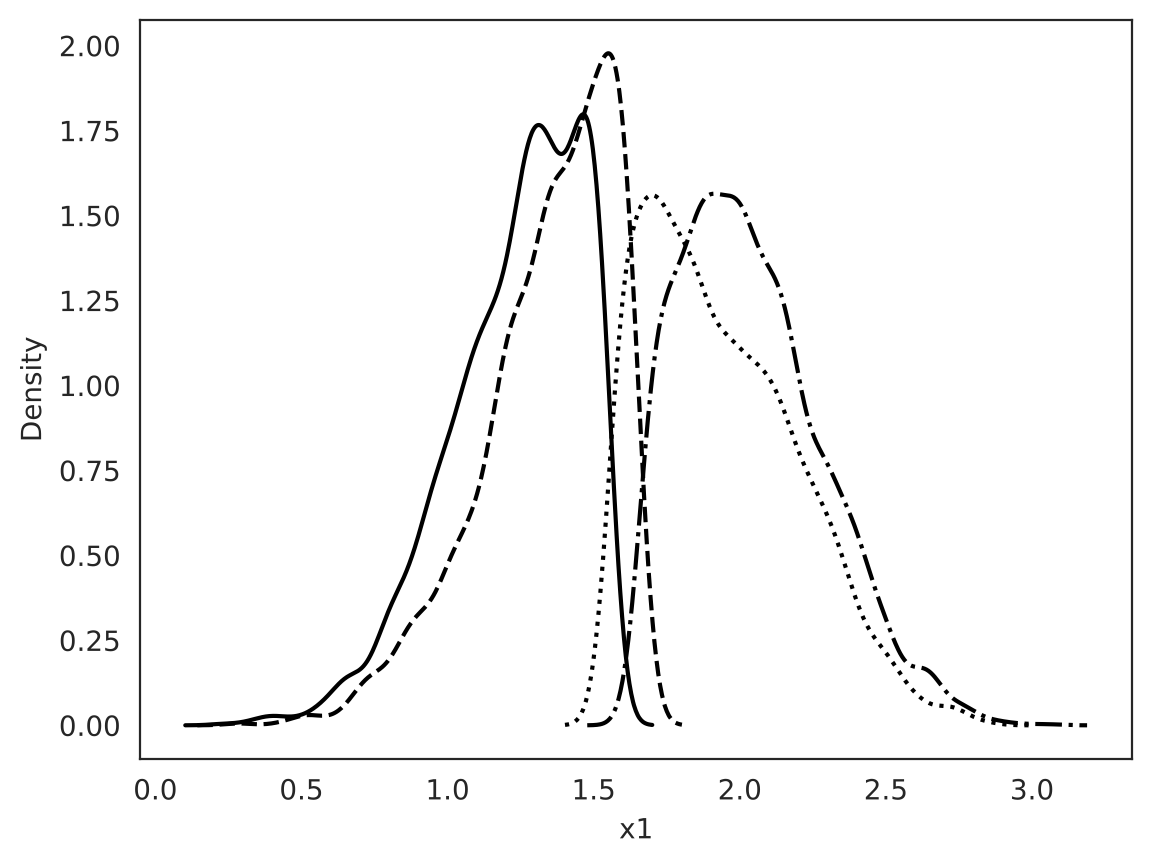

In [17]:
# density of the first signal for each estimated type
styles = ['-', '--', ':', '-.']
for k in range(0, 4):
    d_x, d_y = density(x1[a['t'] == k])
    plt.plot(d_x, d_y, color='k', linestyle=styles[k])
plt.xlabel('x1')
plt.ylabel('Density')
plt.show()

In [18]:
# mean of the first signal for each estimated type
# a['t'] is 0 for the first type (a$t==1 in R), 1 for the second, ...
# the true values are 1.25, 1.5, 1.75 and 2
# (1.75 is the type 3, which no observation has here)
for k in range(0, 4):
    print(np.mean(x1[a['t'] == k]))

1.2354722555575095
1.3459469760885814
1.934217160398151
2.039008476847227


## 12.4.2 Twin Reports Data

In [19]:
# using statsmodels for the regressions, as in the previous chapters
import statsmodels.formula.api as sm
from statsmodels.iolib.summary2 import summary_col

# pandas reads the Stata data sets (the R package foreign in the book)
x = pd.read_stata('../data/pubtwins.dta')

# the variable first is missing for the second twin of each pair
xf = x[x['first'].isna() == False]  # first twin
xs = x[x['first'].isna() == True]  # second twin
# educ    : Twin1 Education
# educt   : Twin1 Report of Twin2 Education
# educ_t  : Twin2 Education
# educt_t : Twin2 Report of Twin1 Education
# the data is written out in pairs for each set of twins.

lm1 = sm.ols(formula="dlwage ~ deduc", data=xf).fit()
lm2 = sm.ols(formula="dlwage ~ deduc + duncov + dmaried + dtenure",
             data=xf).fit()

In [20]:
# function of chapter 1 to plot a line from slope and intercept
# credits to David Marx https://stackoverflow.com/questions/7941226/how-to-add-line-based-on-slope-and-intercept-in-matplotlib/43811762

def abline(slope, intercept):
    """Plot a linear function from slope and intercept"""
    axes = plt.gca()
    x_vals = np.array(axes.get_xlim())
    y_vals = intercept + slope * x_vals
    plt.plot(x_vals, y_vals, color='dimgray')

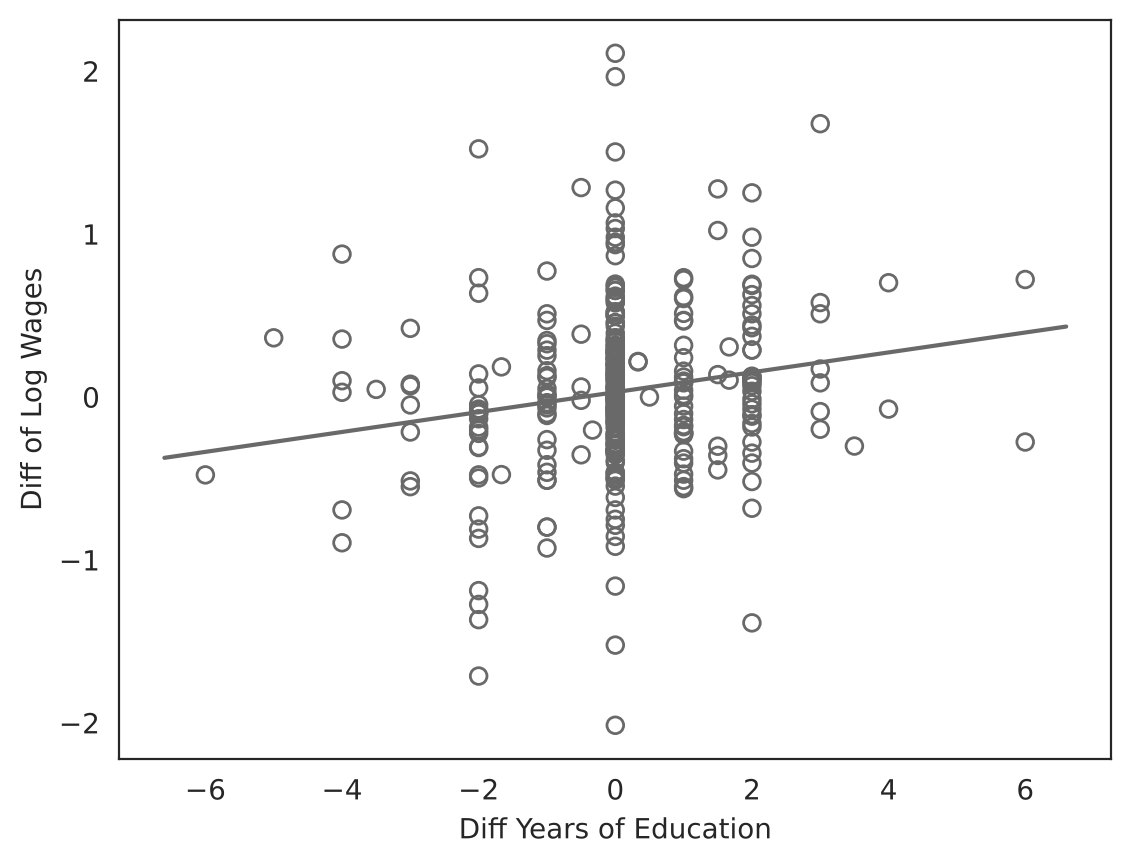

In [21]:
# wage differences by differences in education reports
plt.scatter(xf['deduc'], xf['dlwage'], facecolors='none', color='dimgray')
# the line is the regression from above
abline(intercept=lm1.params['Intercept'], slope=lm1.params['deduc'])
plt.xlabel('Diff Years of Education')
plt.ylabel('Diff of Log Wages')
plt.show()

## 12.4.3 Mixture Model Approach to Measurement Error

In [22]:
# the seed of the book (with a matrix of centers, nothing is random in our function)
np.random.seed(123456789)

# two signals of the education level of each twin:
# his own report and the report of his sibling
yf = np.c_[xf['educ'], xf['educt_t']]
ys = np.c_[xs['educ'], xs['educt_t']]
# np.r_ puts the rows of ys under the rows of yf (rbind in R)
y1 = np.r_[yf, ys]

The data is recombined to estimate the mixture model.

In [23]:
# four types, both signals start at 12, 14, 16 and 18 years
centers = np.c_[[12, 14, 16, 18], [12, 14, 16, 18]]
b1 = mixmod_fun(y1, centers, tol=1e-25)

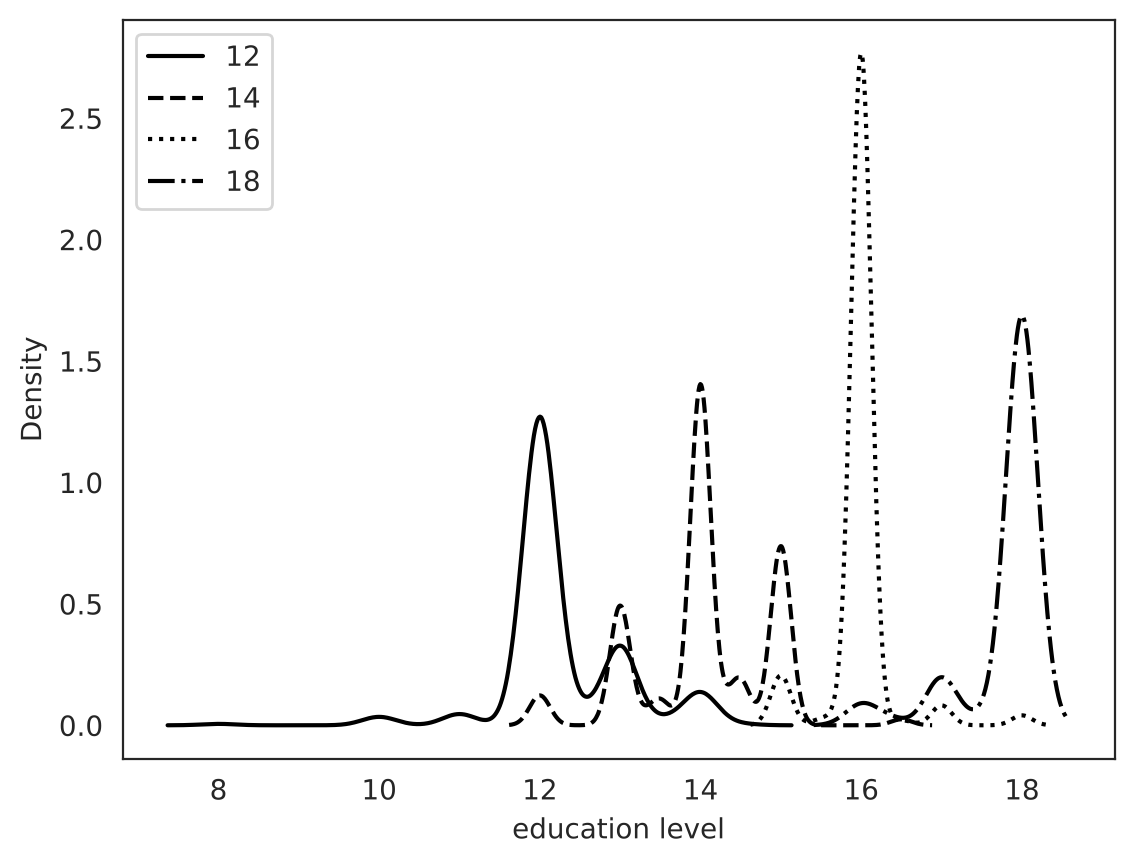

In [24]:
# density of the twin's own report for each estimated type
styles = ['-', '--', ':', '-.']
labels = ['12', '14', '16', '18']
for k in range(0, 4):
    d_x, d_y = density(y1[b1['t'] == k, 0])
    plt.plot(d_x, d_y, color='k', linestyle=styles[k], label=labels[k])
plt.xlabel('education level')
plt.ylabel('Density')
plt.legend(loc='upper left')
plt.show()

## 12.4.4 Estimating Returns to Schooling from Twins

In [25]:
ed = np.array([12, 14, 16, 18])

# difference in "true" education levels
# for each twin
# the first 340 rows of gamma are the first twins (rows 0 to 339 in python)
# and the next 340 rows are the second twins
xf['deduc'] = b1['gamma'][0:340, :].dot(ed) - b1['gamma'][340:680, :].dot(ed)

lm3 = sm.ols(formula="dlwage ~ deduc", data=xf).fit()
lm4 = sm.ols(formula="dlwage ~ deduc + duncov + dmaried + dtenure",
             data=xf).fit()

In [26]:
# (1) and (2) are the first difference estimates
# (3) and (4) are the mixture model estimates
print(summary_col([lm1,lm2,lm3,lm4],
                  stars=True,
                  float_format='%0.3f',
                  model_names=['(1)','(2)','(3)','(4)'],
                  info_dict={'N':lambda x: "{0:d}".format(int(x.nobs)),
                             'R2':lambda x: "{:.3f}".format(x.rsquared)}
            ))


                 (1)      (2)      (3)      (4)   
--------------------------------------------------
Intercept      0.030    0.026    0.032    0.030   
               (0.028)  (0.026)  (0.027)  (0.026) 
deduc          0.061*** 0.073*** 0.068*** 0.082***
               (0.019)  (0.018)  (0.019)  (0.018) 
duncov                  0.086             0.085   
                        (0.056)           (0.055) 
dmaried                 0.024             0.049   
                        (0.073)           (0.073) 
dtenure                 0.023***          0.024***
                        (0.003)           (0.003) 
R-squared      0.031    0.170    0.036    0.178   
R-squared Adj. 0.028    0.160    0.033    0.168   
N              340      333      340      333     
R2             0.031    0.170    0.036    0.178   
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


## 12.5.1 Restaurant Employment

In [27]:
# same data as in chapter 10 (Card and Krueger 1994)
# the first column of the file has no name: these are the row numbers of R
x = pd.read_csv('../data/cardkrueger.csv', index_col=0)

In [28]:
# We take the functions of chapter 10 to clean the data

def get_period(df, ft, pt, time):
    """
    We keep the variables of one period:
    * SHEET is the firm ID
    * FT - fulltime, PT - parttime
    * TIME is the time period (1 or 2)
    """
    d = pd.DataFrame({'SHEET': df['SHEET'],
                      'FT': df[ft],
                      'PT': df[pt],
                      'STATE': df['STATE'],
                      'TIME': time})
    return d

def fix_labels(df):
    # there is an issue with the labeling in the data.
    # two firms with the same label.
    df.loc[df['SHEET'] == 407, 'SHEET'] = [4071, 4072]
    return df

def convert_col_to_numeric(df, col):
    # values which are not numbers (here ".") become NAs
    df[col] = pd.to_numeric(df[col], errors='coerce')
    return df

In [29]:
# and we perform the data cleaning using the .pipe operator
# on the original dataset x

# this includes the initial employment levels.
x1 = (
    x
    .pipe(get_period, ft='EMPFT', pt='EMPPT', time=1)
    .pipe(fix_labels)
)

# the second period of data.
x2 = (
    x
    .pipe(get_period, ft='EMPFT2', pt='EMPPT2', time=2)
    .pipe(fix_labels)
)

# putting both periods together.
# FT and PT are read as text because of the "." in the file,
# we change them into numbers
x3 = (
    pd.concat([x1, x2], ignore_index=True)
    .pipe(convert_col_to_numeric, col='FT')
    .pipe(convert_col_to_numeric, col='PT')
)

In [30]:
# a matrix with 4 rows and one column per restaurant
Y = np.array([x3['FT'][x3['TIME']==1], x3['PT'][x3['TIME']==1],
              x3['FT'][x3['TIME']==2], x3['PT'][x3['TIME']==2]])

# we keep the restaurants with no missing value in the 4 rows
index_na = np.isnan(np.sum(Y, axis=0)) == False
Y1 = Y[0:2, index_na]  # period 1
Y2 = Y[2:4, index_na]  # period 2

# True for New Jersey (treated), False for Pennsylvania
treat = np.array(x3['STATE'][x3['TIME']==1] == 1)
treat1 = treat[index_na]

In [31]:
# number of full-time and part-time employees in period 1
# .T to have one row per restaurant
pd.DataFrame(Y1.T, columns=['Full-Time', 'Part-Time']).describe()

,Full-Time,Part-Time
count,391.000000,391.000000
mean,8.202046,18.842711
std,8.680222,10.181944
min,0.000000,0.000000
25%,2.000000,11.000000
50%,6.000000,17.000000
75%,11.250000,25.000000
max,60.000000,60.000000


## 12.5.2 Mixture Model Estimation of Restaurant Type

In [32]:
p1 = np.array([2, 6, 2, 2, 6])
p2 = np.array([11, 17, 17, 25, 11])
a = mixmod_fun(X=Y1.T, centers=np.c_[p1, p2], tol=1e-15)
a['g']

array([0.30724141, 0.07859604, 0.26042828, 0.17348538, 0.18024888])

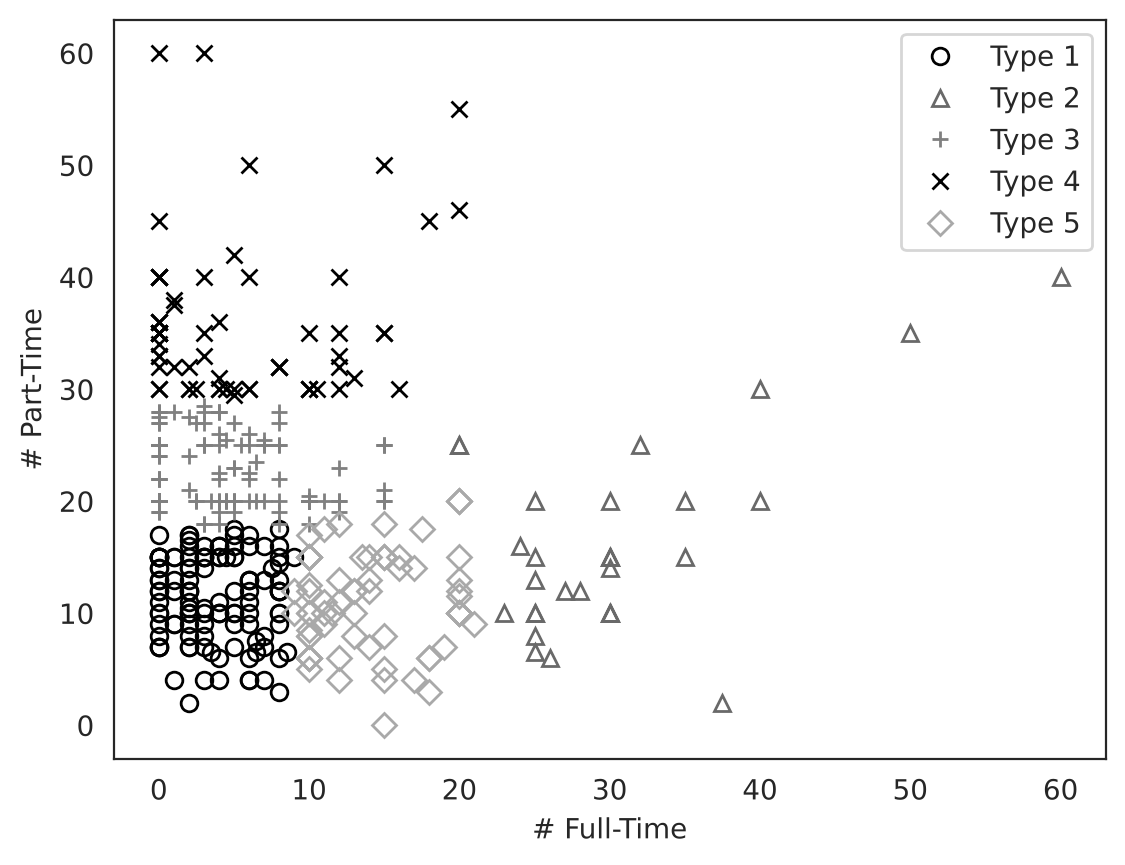

In [33]:
# full-time and part-time employees in period 1, by hidden type
# a['t'] is 0 for the type 1 of the book, 1 for the type 2, ...
markers = ['o', '^', '+', 'x', 'D']
colors = ['k', 'dimgray', 'grey', 'k', 'darkgrey']
for k in range(0, 5):
    plt.plot(Y1[0, a['t'] == k], Y1[1, a['t'] == k],
             linestyle='none', marker=markers[k], fillstyle='none',
             color=colors[k], label='Type ' + str(k+1))
plt.xlabel('# Full-Time')
plt.ylabel('# Part-Time')
plt.legend(loc='upper right')
plt.show()

## 12.5.3 Heterogeneous Minimum Wage Effect

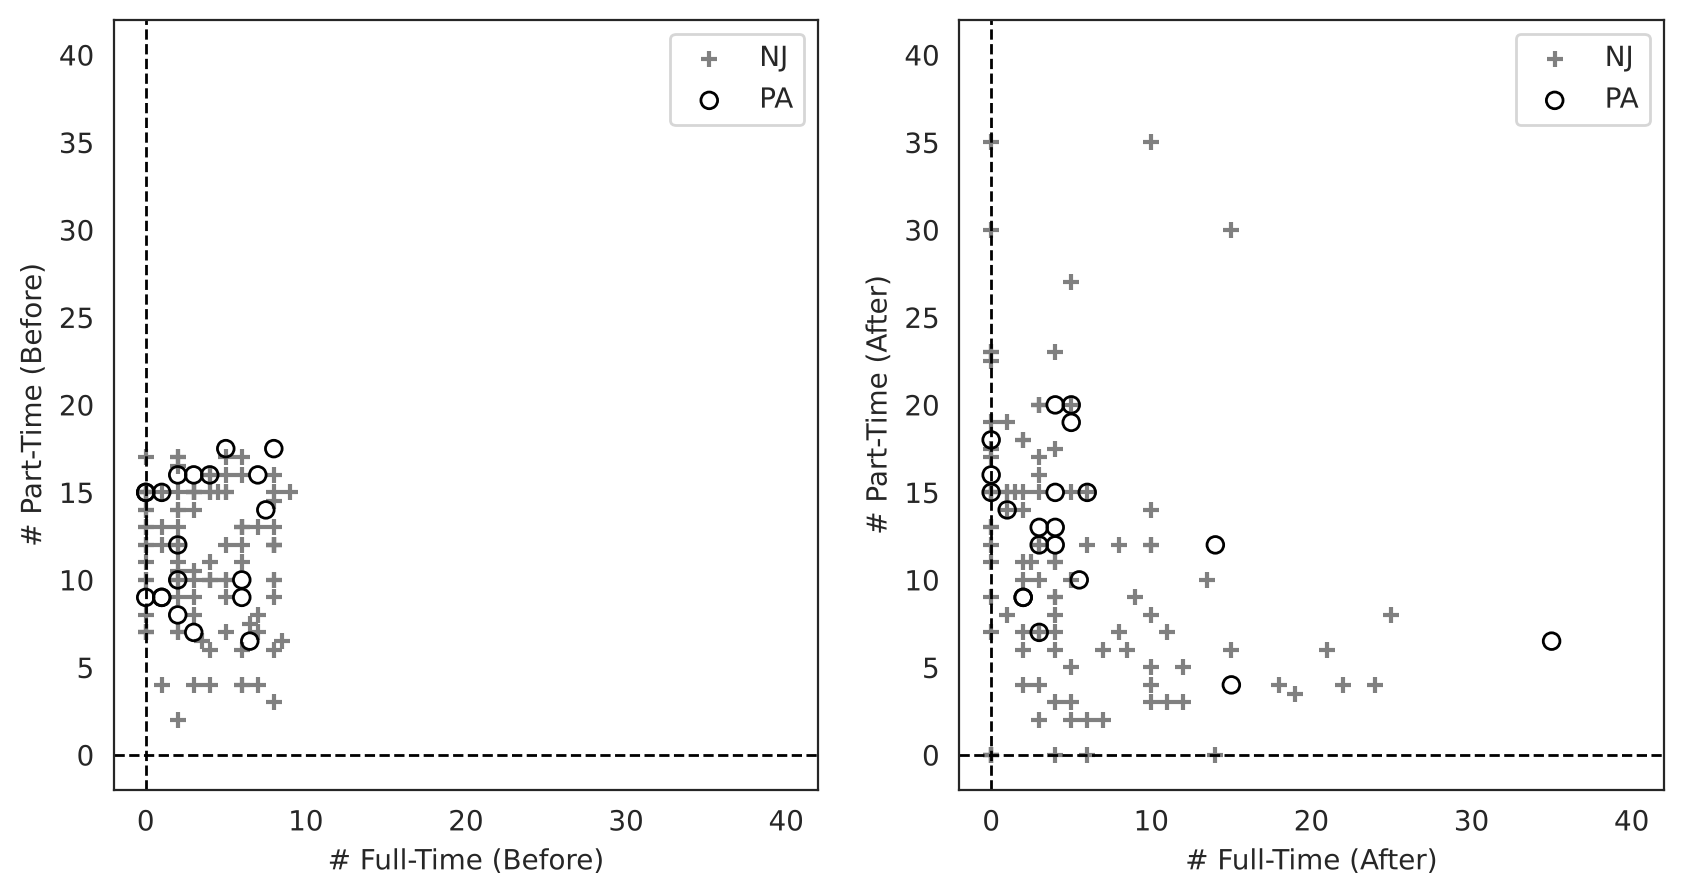

In [34]:
# type 1 restaurants (small restaurants) in each state
# type 1 of the book is type 0 in python
pa_1 = (treat1 == False) & (a['t'] == 0)
nj_1 = (treat1 == True) & (a['t'] == 0)

plt.figure(figsize=(10, 5))

# before the minimum wage increase (left)
plt.subplot(1, 2, 1)
plt.scatter(Y1[0, nj_1], Y1[1, nj_1], marker='+', color='grey', label='NJ')
plt.scatter(Y1[0, pa_1], Y1[1, pa_1], facecolors='none', color='k', label='PA')
plt.axhline(0, color='k', linestyle='--', linewidth=1)
plt.axvline(0, color='k', linestyle='--', linewidth=1)
plt.xlim(-2, 42)
plt.ylim(-2, 42)
plt.xlabel('# Full-Time (Before)')
plt.ylabel('# Part-Time (Before)')
plt.legend(loc='upper right')

# after the minimum wage increase (right)
plt.subplot(1, 2, 2)
plt.scatter(Y2[0, nj_1], Y2[1, nj_1], marker='+', color='grey', label='NJ')
plt.scatter(Y2[0, pa_1], Y2[1, pa_1], facecolors='none', color='k', label='PA')
plt.axhline(0, color='k', linestyle='--', linewidth=1)
plt.axvline(0, color='k', linestyle='--', linewidth=1)
plt.xlim(-2, 42)
plt.ylim(-2, 42)
plt.xlabel('# Full-Time (After)')
plt.ylabel('# Part-Time (After)')
plt.legend(loc='upper right')

plt.show()

In [35]:
def f_did(Y, treat):
    """
    Difference in difference estimator of chapter 10
    * Y is a matrix with 2 rows (period 1 and period 2)
      and one column per restaurant
    * treat is 1 for the treated restaurants and 0 for the others
    """
    y1 = Y[0, :]
    y2 = Y[1, :]
    # creates the difference in difference matrix
    did = np.zeros((3, 3))
    # calculates the average outcomes for each
    did[0, 0] = np.mean(y2[treat == 1])
    did[1, 0] = np.mean(y1[treat == 1])
    did[0, 1] = np.mean(y2[treat == 0])
    did[1, 1] = np.mean(y1[treat == 0])
    # calculates the differences.
    did[2, 0] = did[0, 0] - did[1, 0]
    did[2, 1] = did[0, 1] - did[1, 1]
    did[0, 2] = did[0, 0] - did[0, 1]
    did[1, 2] = did[1, 0] - did[1, 1]
    did[2, 2] = did[2, 0] - did[2, 1]
    # name the rows and the columns of the matrix
    did = pd.DataFrame(did,
                       index=['Period 2', 'Period 1', 'Diff'],
                       columns=['Treated', 'Not Treated', 'Diff'])
    return did

In [36]:
# full-time employment for type 1 restaurants
# prior to the minimum wage increase
# (first the restaurants of Pennsylvania, then the ones of New Jersey)
y_11 = np.r_[Y1[0, pa_1], Y1[0, nj_1]]
# full-time employment for type 1 restaurants after
# the minimum wage increase.
y_12 = np.r_[Y2[0, pa_1], Y2[0, nj_1]]
# 0 for Pennsylvania and 1 for New Jersey
treat = np.r_[np.zeros(np.sum(pa_1)), np.ones(np.sum(nj_1))]

did1 = f_did(np.array([y_11, y_12]), treat)

# difference in difference, as a share of the employment
# of the treated restaurants in period 2 (did1[3,3]/did1[1,1] in R)
print(did1.loc['Diff', 'Diff']/did1.loc['Period 2', 'Treated'])

-0.17107750472589797


In [37]:
# same thing for part-time employment (second row of Y1 and Y2)
y_13 = np.r_[Y1[1, pa_1], Y1[1, nj_1]]
y_14 = np.r_[Y2[1, pa_1], Y2[1, nj_1]]
treat = np.r_[np.zeros(np.sum(pa_1)), np.ones(np.sum(nj_1))]

did2 = f_did(np.array([y_13, y_14]), treat)
print(did2.loc['Diff', 'Diff']/did2.loc['Period 2', 'Treated'])

-0.08023572076155937


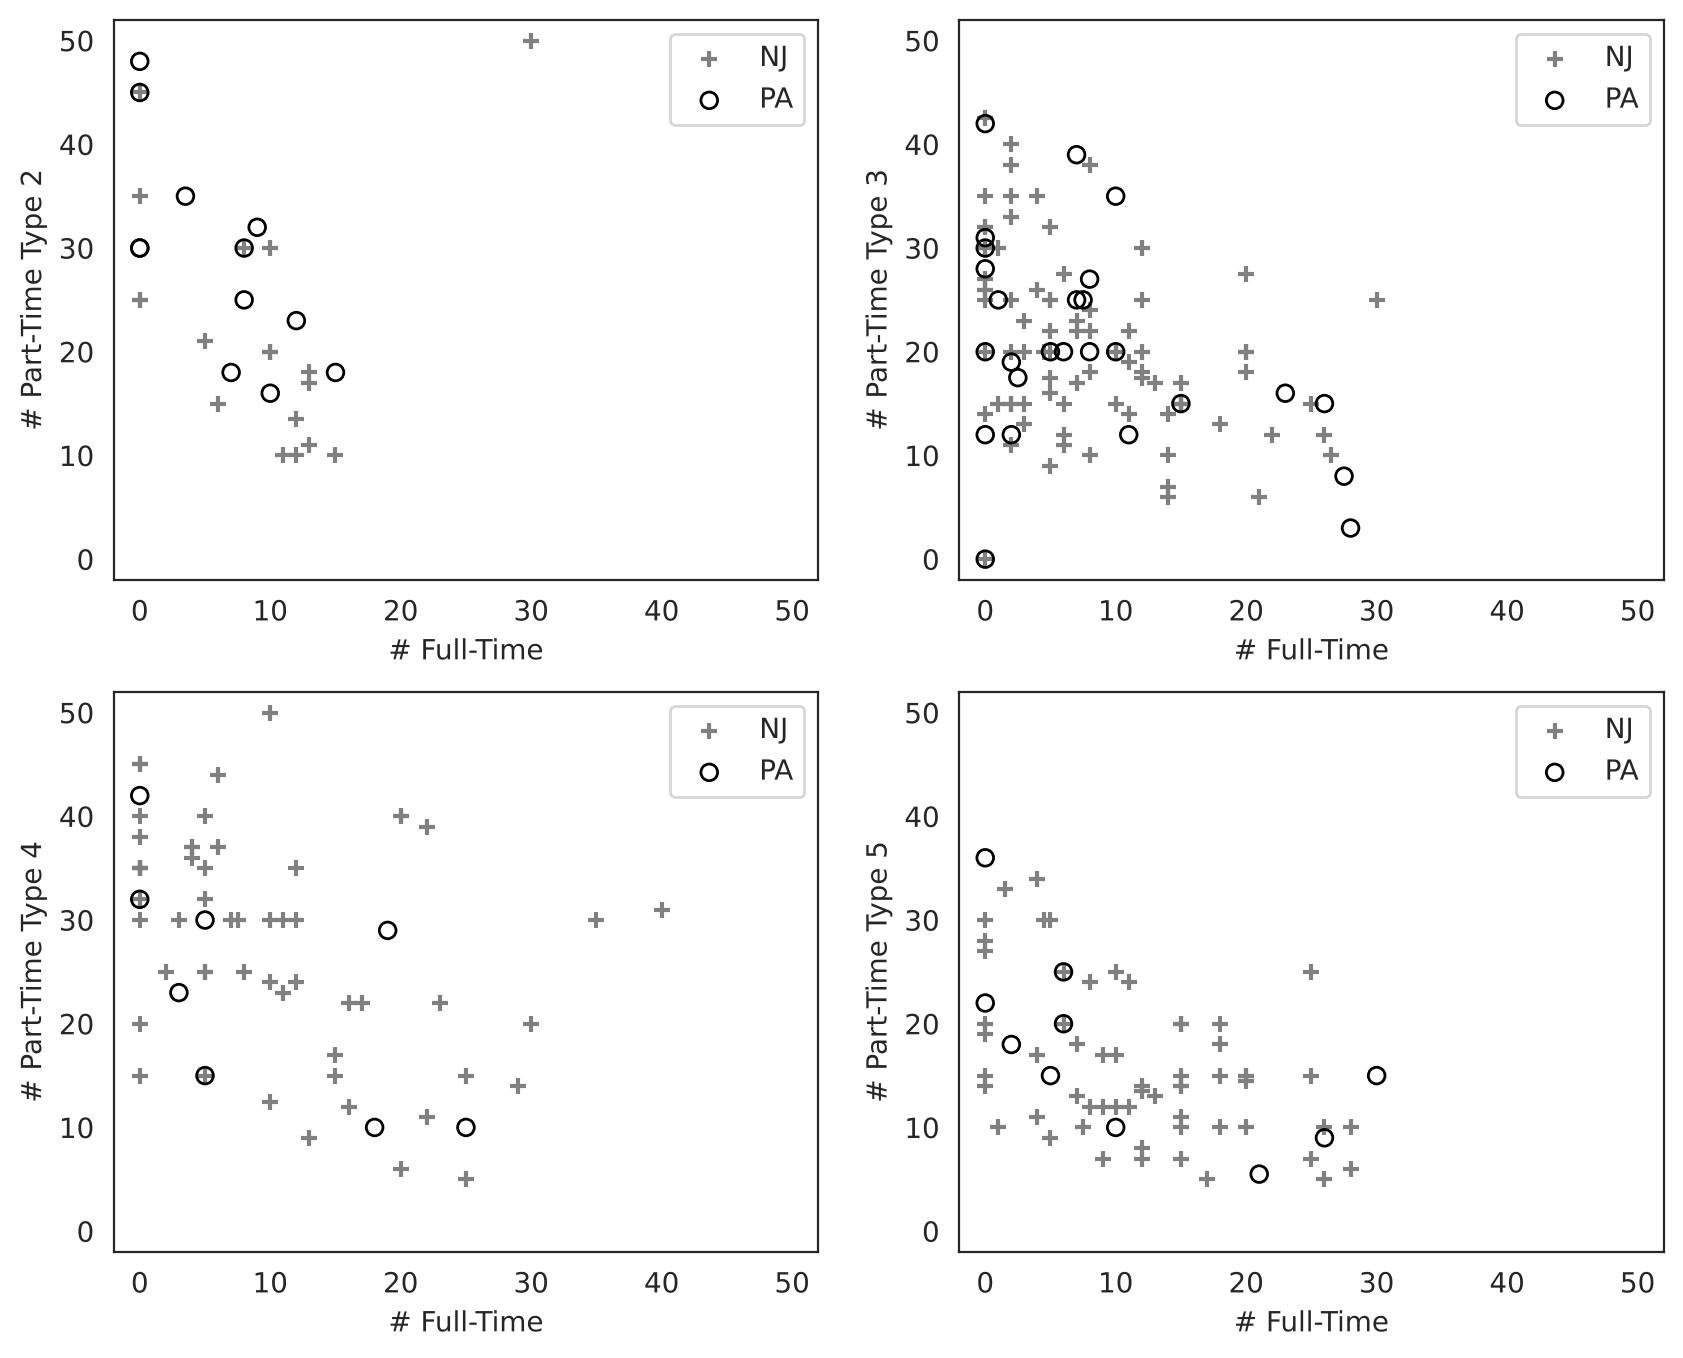

In [38]:
# full-time and part-time employees for the types 2 to 5
# after the minimum wage increase
plt.figure(figsize=(10, 8))

for k in range(1, 5):
    pa_k = (treat1 == False) & (a['t'] == k)
    nj_k = (treat1 == True) & (a['t'] == k)
    # 2 rows and 2 columns of plots
    # k is 1 for the type 2 of the book, which goes in the plot number 1
    plt.subplot(2, 2, k)
    plt.scatter(Y2[0, nj_k], Y2[1, nj_k], marker='+', color='grey', label='NJ')
    plt.scatter(Y2[0, pa_k], Y2[1, pa_k], facecolors='none', color='k', label='PA')
    plt.xlim(-2, 52)
    plt.ylim(-2, 52)
    plt.xlabel('# Full-Time')
    plt.ylabel('# Part-Time Type ' + str(k+1))
    plt.legend(loc='upper right')

plt.show()